# Paper example: XXZ chain

This notebook runs an adapted version of the PyGFMC paper's example code (20 sites, fixed seeds, 2000 steps).

In [1]:
import jax
import jax.numpy as jnp
import numpy as np

from pygfmc import run
from pygfmc.hamiltonian import (SpinHalf, StructureFactor, SzSzStructureFactor,
                                exact_diagonalization, is_valid_k)
from pygfmc.walkers import prepare_walkers_sz
from pygfmc.wavefunction import JastrowSpinHalf

# Fixed master RNG, so the stored outputs can be reproduced; split off subkeys
# as needed in each cell below.
rng = jax.random.PRNGKey(0)

print(f'JAX version : {jax.__version__}')
print(f'Backend     : {jax.default_backend()}')

JAX version : 0.9.2
Backend     : cpu


## 1. Hamiltonian

The model is an XXZ chain with periodic boundary conditions,

$$H \;=\; \sum_{\langle i,j\rangle}\!\Big[\,J^{xy}_{ij}\,(S^x_i S^x_j + S^y_i S^y_j) \;+\; J^{z}\, S^z_i S^z_j\,\Big] \;-\; \sum_i h^{z}_i\, S^z_i\,,$$

with random per-bond transverse couplings $J^{xy}_{ij} \in [-1.2,\,-0.8]$, uniform Ising coupling $J^z = 1$, and a linear longitudinal field $h^z_i \in [-0.3,\,0.3]$.

In [2]:
L     = 20
edges = [(i, (i + 1) % L) for i in range(L)]

J_xy  = -np.random.default_rng(1).uniform(0.8, 1.2, size=len(edges))  # random per-bond, fixed seed
h_z   = np.linspace(-0.3, 0.3, L)                      # non-uniform field

H = SpinHalf.create(
    edges,
    J_x=J_xy, J_y=J_xy,     # random per-edge XY
    J_z=1.0,                # uniform Ising coupling
    h_z=h_z,                # per-site longitudinal field
)

print(f'N (sites) = {H.N}')
print(f'J_xy      = {np.round(J_xy, 3)}')
print(f'h_z       = {np.round(h_z, 3)}')

N (sites) = 20
J_xy      = [-1.005 -1.18  -0.858 -1.179 -0.925 -0.969 -1.131 -0.964 -1.02  -0.811
 -1.101 -1.015 -0.932 -1.115 -0.921 -0.981 -0.854 -0.961 -0.881 -0.905]
h_z       = [-0.3   -0.268 -0.237 -0.205 -0.174 -0.142 -0.111 -0.079 -0.047 -0.016
  0.016  0.047  0.079  0.111  0.142  0.174  0.205  0.237  0.268  0.3  ]


## 2. Walker ensemble

We initialize every walker in the $S^z_{\rm tot} = 0$ sector.

In [3]:
rng, key = jax.random.split(rng)
walkers  = prepare_walkers_sz(N_walkers=512, N_sites=H.N, rng_key=key, sz=0)

Sz_tot = np.asarray(walkers.config).sum(axis=1) / 2.0
print(f'walker config shape : {walkers.config.shape}')
print(f'S^z_tot per walker  : min={Sz_tot.min():.3f}, max={Sz_tot.max():.3f}, mean={Sz_tot.mean():.3f}')

walker config shape : (512, 20)
S^z_tot per walker  : min=0.000, max=0.000, mean=0.000


## 3. Guiding wavefunction

A one-parameter Ising-type Jastrow, $\psi_T(x) = \exp(-\beta \sum_{\langle ij\rangle} x_i x_j)$ on the Hamiltonian edges. We optimize $\beta$ with [NetKet](https://www.netket.org) using the function `train_with_netket`.

In [4]:
import os
os.environ["NETKET_NO_TIPS"] = "1"   # silence NetKet's tips
from pygfmc.wavefunction import train_with_netket   # imports NetKet on the first call

guide = JastrowSpinHalf(H.N, H.edges, beta=0.1)
guide, history = train_with_netket(H, guide, return_history=True)

print(f'beta = {float(guide.beta[0]):.4f}')
print(f'variational energy: {history[0]:.5f} (beta = 0.1) -> {np.mean(history[-10:]):.5f} (trained)')

beta = 0.2874
variational energy: -7.17065 (beta = 0.1) -> -8.39799 (trained)


## 4. Observables

We use `SpinHalf` to build the observables. `SpinHalf` writes the fields as $-\sum_i h^x_i S^x_i$, so the observable $\sum_i S^x_i$ is constructed with `h_x=-1` at every site. This gives non-negative off-diagonal matrix elements. Set `sign_check=False` to disable the constructor's Hamiltonian sign check for this measurement operator.

The structure factors are built from the site positions. `SzSzStructureFactor` is diagonal and measures $S^{zz}(k)$ at all allowed $k$ of the ring at once; the $i = j$ terms are left out, so $S^{zz}(0) = [(\sum_i \sigma^z_i)^2 - N]/4 = -N/4$ in the $S^z_{\rm tot} = 0$ sector. `StructureFactor` is off-diagonal and measures $AB(0) + AB(k)$ for $A = S^+$, $B = S^-$ at a single $k$, here $k = \pi$.

In [5]:
h_all = jnp.ones(L)
h_0   = jnp.zeros(L).at[0].set(1.0)

# the fields enter H with a minus sign, so +sum_i S^z_i needs h_z = -1 (and
# +sum_i S^x_i needs h_x = -1, which gives the non-negative rates an
# off-diagonal observable requires)
Sztot = SpinHalf.create(edges=[], N=L, h_z=-h_all)
Sz0   = SpinHalf.create(edges=[], N=L, h_z=-h_0)
Sxtot = SpinHalf.create(edges=[], N=L, h_x=-h_all, sign_check=False)
Sx0   = SpinHalf.create(edges=[], N=L, h_x=-h_0,   sign_check=False)

# structure factors: all allowed k of the L-site ring at once
positions = jnp.arange(L)[:, None]                    # (N, dim)
k_vectors = 2 * jnp.pi * jnp.arange(L)[:, None] / L   # (n_k, dim)

# every k must be compatible with the periodic boundary conditions,
# k . L = 2 pi * integer for the lattice vector L of the ring
lattice_vectors = jnp.array([[L]])
print('all k vectors valid:', bool(is_valid_k(k_vectors, lattice_vectors).all()))

Szz = SzSzStructureFactor(positions, k_vectors)
Spm = StructureFactor(positions, k_vectors[L // 2], channel='SpSm')

diag_operators     = {'Sztot': Sztot, 'Sz0': Sz0, 'Szz': Szz}
off_diag_operators = {'Sxtot': Sxtot, 'Sx0': Sx0, 'Spm': Spm}

# exact reference for the energy and all observables
E_ed, diag_ed, off_ed = exact_diagonalization(H, diag_operators=diag_operators,
                                              off_diag_operators=off_diag_operators)
print(f'exact E0 = {E_ed[0]:.6f}')


all k vectors valid: True


exact E0 = -8.930191


## 5. Simulation driver

We run for `n_steps = 2000` production branching steps with the default continuous-time propagator, imaginary time `step_size = 0.5` per step, and five projection windows `p = 4, 8, 16, 32, 48`. Fresh walkers need a warm-up.

In [6]:
rng, key = jax.random.split(rng)
walkers, energy, obs, stats, raw = run(
    walkers,
    n_steps=2000,
    hamiltonian=H,
    step_size=0.5,
    guide=guide,
    p_array=[4, 8, 16, 32, 48],
    rng_key=key,
    warmup_steps=500,
    diag_operators=diag_operators,
    off_diag_operators=off_diag_operators,
    number_of_outputs=20,
    verbosity=8,
)

[gfmc] - [run_warmup 1/4] - step=0.0625, 125 steps @ 36.0 it/s, avg_log_weight = 8.779625


[gfmc] - [run_warmup 2/4] - step=0.125, 125 steps @ 52.5 it/s, avg_log_weight = 8.915340


[gfmc] - [run_warmup 3/4] - step=0.25, 125 steps @ 50.3 it/s, avg_log_weight = 8.934429


[gfmc] - [run_warmup 4/4] - step=0.5, 125 steps @ 49.4 it/s, avg_log_weight = 8.919834


[estimators] - [check_off_diag_operator_positivity] - all operators passed positivity check (100 configs, 3 operators)


...

[gfmc] - [run_gfmc] - step: 1700/2000, 2.5 it/s, N_config = 362/512 (70.7%) Energy[p]: {4: -8.929048310239564, 8: -8.929236425571487, 16: -8.929422292232966, 32: -8.929300995483974, 48: -8.929473495155456}
[gfmc] - [run_gfmc] - operators: {'Sztot': {4: 0.0, 8: 0.0, 16: 0.0, 32: 0.0, 48: 0.0}, 'Sxtot': {4: 4.286568798862448, 8: 3.2531986999140745, 16: 2.053247008972882, 32: 0.9039993415712403, 48: 0.40674554845218874}}


[gfmc] - [run_gfmc] - step: 1800/2000, 2.5 it/s, N_config = 374/512 (73.0%) Energy[p]: {4: -8.92854253602734, 8: -8.928746913687444, 16: -8.92894805512665, 32: -8.928862997234107, 48: -8.929070119702816}
[gfmc] - [run_gfmc] - operators: {'Sztot': {4: 0.0, 8: 0.0, 16: 0.0, 32: 0.0, 48: 0.0}, 'Sxtot': {4: 4.289086921141327, 8: 3.257635656698996, 16: 2.05806328897828, 32: 0.909148564263865, 48: 0.41034073651088576}}


[gfmc] - [run_gfmc] - step: 1900/2000, 2.4 it/s, N_config = 377/512 (73.6%) Energy[p]: {4: -8.928954694733207, 8: -8.929138945238789, 16: -8.929299911204954, 32: -8.929198510675644, 48: -8.929499416995151}
[gfmc] - [run_gfmc] - operators: {'Sztot': {4: 0.0, 8: 0.0, 16: 0.0, 32: 0.0, 48: 0.0}, 'Sxtot': {4: 4.289578770273059, 8: 3.2563997485646246, 16: 2.0557545892791675, 32: 0.9062261661817191, 48: 0.4084832398544868}}


[gfmc] - [run_gfmc] - step: 2000/2000, 1.9 it/s, N_config = 374/512 (73.0%) Energy[p]: {4: -8.929282385811526, 8: -8.929487655618349, 16: -8.92962545722061, 32: -8.92942223743614, 48: -8.929690680206061}
[gfmc] - [run_gfmc] - operators: {'Sztot': {4: 0.0, 8: 0.0, 16: 0.0, 32: 0.0, 48: 0.0}, 'Sxtot': {4: 4.287908878604324, 8: 3.253224213229379, 16: 2.052109733949777, 32: 0.9049433704552644, 48: 0.40732644414961855}}


[estimators] - [statistics] - 10 branching steps (+14 lineage-only)
[estimators] - [statistics] - N_walkers: 512
[estimators] - [statistics] - step_size: 0.5
[estimators] - [statistics] - lam: not used
[estimators] - [statistics] - avg_log_weight: 8.919834
[estimators] - [statistics] - unique (pre): 377.2 ± 11.7  (73.7%)
[estimators] - [statistics] - unique (post): 377.3 ± 11.7  (73.7%)
[estimators] - [statistics] - H_diag: min=-5.1579, max=0.6000  (observed max over the 10 health steps)
[estimators] - [statistics] - escape rate: min=3.1220, max=12.2120
[estimators] - [statistics] - hops per branching step (Gamma*step_size): mean=2.904, max=6.106
[estimators] - [statistics] - escape rate Gamma: mean=5.809, min=3.122, max=12.212
[estimators] - [statistics] - hold time (a draw of 1/Gamma, not hops per step): mean=0.1832, max=2.2619
[estimators] - [statistics] - changed (per-index): 99.5% avg over 10 steps
[estimators] - [statistics] - overlap (pop):       17.1% avg over 10 steps
[estimat

## 6. Inspect the raw output

`raw` holds the per-step GFMC series and the metadata needed to re-evaluate them.

In [7]:
print('raw keys :', sorted(raw.keys()))
print()
for key in sorted(raw.keys()):
    val = raw[key]
    if isinstance(val, dict):
        print(f'  {key:18s} : dict ' + ', '.join(f'{k}: {tuple(np.shape(v))}' for k, v in val.items()))
    elif hasattr(val, 'shape'):
        print(f'  {key:18s} : shape={tuple(val.shape)}  dtype={val.dtype}')
    else:
        print(f'  {key:18s} : {val!r}')

raw keys : ['additional_diag', 'diag', 'diag_operators', 'energy', 'log_weights', 'm_array', 'off_diag', 'off_diag_norm', 'off_diag_operators', 'off_diag_steps', 'p_array']

  additional_diag    : dict Sztot: (24, 5), Sz0: (24, 5), Szz: (24, 20, 5)
  diag               : dict Sztot: (2000, 5), Sz0: (2000, 5), Szz: (2000, 20, 5)
  diag_operators     : ['Sztot', 'Sz0', 'Szz']
  energy             : shape=(2000,)  dtype=float32
  log_weights        : shape=(2000,)  dtype=float32
  m_array            : [2, 4, 8, 16, 24]
  off_diag           : dict Sxtot: (2000, 5), Sx0: (2000, 5), Spm: (2000, 5)
  off_diag_norm      : dict Sxtot: (2000, 5), Sx0: (2000, 5), Spm: (2000, 5)
  off_diag_operators : ['Sxtot', 'Sx0', 'Spm']
  off_diag_steps     : shape=(2000,)  dtype=int64
  p_array            : [4, 8, 16, 32, 48]


In [8]:
n_show = 5   # how many leading entries to print per series

print(f'log_weights[:{n_show}] =', np.asarray(raw['log_weights'])[:n_show])
print(f'energy[:{n_show}]      =', np.asarray(raw['energy'])[:n_show])
print(f'avg_log_weight    = {stats["avg_log_weight"]:.6f}')
print(f'it_per_sec        = {float(stats["it_per_sec"]):.1f}')

print(f'\ndiag:     operator -> (n_steps, [n_k,] len(p_array))', {k: np.shape(v) for k, v in raw['diag'].items()})
print(f'off_diag: operator -> (n_measurements, len(p_array))', {k: np.shape(v) for k, v in raw['off_diag'].items()})

log_weights[:5] = [-0.00926352 -0.01247549 -0.02184439  0.00926638 -0.00603008]
energy[:5]      = [-8.868913 -8.901825 -8.880192 -8.963721 -8.88726 ]
avg_log_weight    = 8.919834
it_per_sec        = 2.5

diag:     operator -> (n_steps, [n_k,] len(p_array)) {'Sztot': (2000, 5), 'Sz0': (2000, 5), 'Szz': (2000, 20, 5)}
off_diag: operator -> (n_measurements, len(p_array)) {'Sxtot': (2000, 5), 'Sx0': (2000, 5), 'Spm': (2000, 5)}


## 7. Final estimates

`evaluate_observables` re-evaluates the energy at any given `p` or the observables at already computed `p` values:

In [9]:
from pygfmc import evaluate_observables

E, O, E_err, O_err = evaluate_observables(raw, n_blocks=20)

print('Energy per site:')
for p in sorted(E):
    print(f'  p = {p:3d}  E/N = {E[p] / H.N:+.6f} +- {E_err[p] / H.N:.6f}')
print(f'  exact      E/N = {E_ed[0] / H.N:+.6f}')

exact = {**diag_ed, **off_ed}
print('\nObservables:')
for name in O:
    if name == 'Szz':
        continue
    line = '  '.join(f'p={p:3d}: {float(O[name][p]):+.4f}' for p in sorted(O[name]))
    print(f'  {name:6s}  {line}   exact: {float(np.ravel(exact[name])[0]):+.4f}')

p_max = max(O['Szz'])
print(f'\nS^zz(k) at p = {p_max}:')
for k, val, err, ex in zip(np.asarray(k_vectors)[:, 0], O['Szz'][p_max], O_err['Szz'][p_max],
                           np.ravel(exact['Szz'])):
    print(f'  k = {k:5.3f}  {float(val):+.4f} +- {float(err):.4f}   exact: {float(ex):+.4f}')


Energy per site:
  p =   4  E/N = -0.446463 +- 0.000107
  p =   8  E/N = -0.446473 +- 0.000107
  p =  16  E/N = -0.446479 +- 0.000107
  p =  32  E/N = -0.446469 +- 0.000102
  p =  48  E/N = -0.446483 +- 0.000107
  exact      E/N = -0.446510

Observables:
  Sztot   p=  4: +0.0000  p=  8: +0.0000  p= 16: +0.0000  p= 32: +0.0000  p= 48: +0.0000   exact: +0.0000
  Sz0     p=  4: -0.1666  p=  8: -0.1912  p= 16: -0.2120  p= 32: -0.2252  p= 48: -0.2279   exact: -0.2306
  Sxtot   p=  4: +4.2881  p=  8: +3.2537  p= 16: +2.0521  p= 32: +0.9049  p= 48: +0.4073   exact: +0.0000
  Sx0     p=  4: +0.2092  p=  8: +0.1535  p= 16: +0.0909  p= 32: +0.0374  p= 48: +0.0165   exact: +0.0000
  Spm     p=  4: +28.8656  p=  8: +25.7020  p= 16: +23.9053  p= 32: +23.3180  p= 48: +23.1681   exact: +23.2687

S^zz(k) at p = 48:
  k = 0.000  -5.0000 +- 0.0000   exact: -5.0000
  k = 0.314  -4.3616 +- 0.0064   exact: -4.3658
  k = 0.628  -3.8201 +- 0.0083   exact: -3.8270
  k = 0.942  -3.1845 +- 0.0109   exact: -3.18

The Hamiltonian conserves the total $S^z$ and every walker stays in the $S^z_\mathrm{tot} = 0$ sector, so $\langle \sum_i S^x_i \rangle$ and $\langle S^x_0 \rangle$ are exactly zero in the ground state (the exact values above); at finite $p$ the estimates are still nonzero because $S^x$ connects the sector to the $S^z_\mathrm{tot} = \pm 1$ sectors, where the Jastrow guide has amplitude, and this contribution is projected out as $p$ grows, so the finite-projection estimates decay towards zero as the projection depth increases.


## 8. Plots

(i) The estimates $O[p]$ of the energy and of every scalar observable as a function of the number of branching steps $p$, with blocked-jackknife error bars; the dashed line is the exact value.
(ii) The structure factor $S^{zz}(k)$ at every allowed $k$, one color per $p$ (light to dark with increasing $p$); the open circles are the exact values, and the lower panel shows the deviation from them.

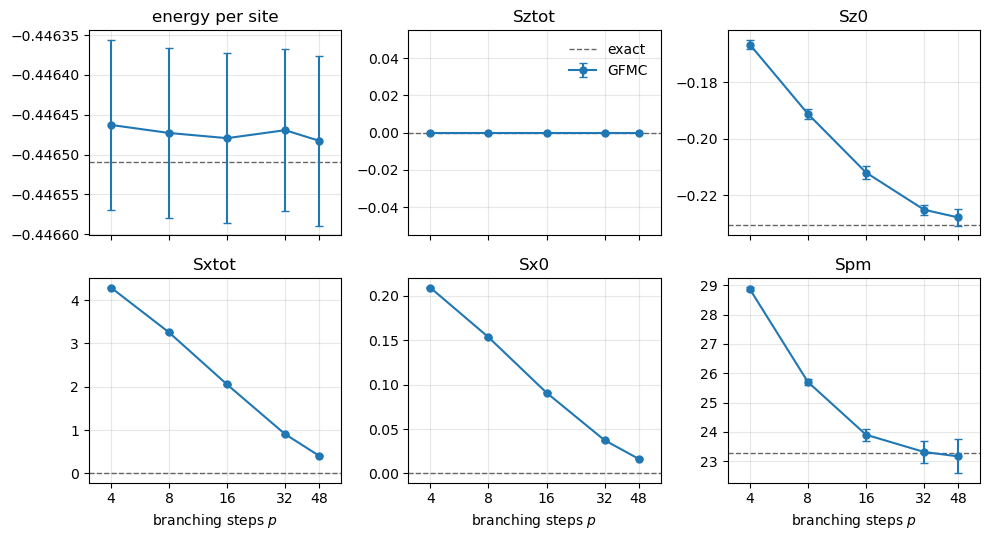

In [10]:
import matplotlib.pyplot as plt

p_values = sorted(E)
panels = [('energy per site', [E[p] / H.N for p in p_values],
           [E_err[p] / H.N for p in p_values], E_ed[0] / H.N)]
for name in O:
    if name == 'Szz':
        continue
    panels.append((name, [float(O[name][p]) for p in p_values],
                   [float(O_err[name][p]) for p in p_values],
                   float(np.ravel(exact[name])[0])))

fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), sharex=True)
for ax, (title, val, err, ex) in zip(axes.flat, panels):
    ax.axhline(ex, color='0.4', ls='--', lw=1, label='exact')
    ax.errorbar(p_values, val, yerr=err, marker='o', ms=5, lw=1.5, capsize=3,
                color='tab:blue', label='GFMC')
    ax.set_title(title)
    ax.set_xscale('log', base=2)
    ax.set_xticks(p_values, [str(p) for p in p_values])
    ax.set_xlim(p_values[0] / 1.3, p_values[-1] * 1.3)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel('branching steps $p$')
axes.flat[1].legend(frameon=False, loc='upper right')   # the flat Sztot panel has room
fig.tight_layout()
plt.show()

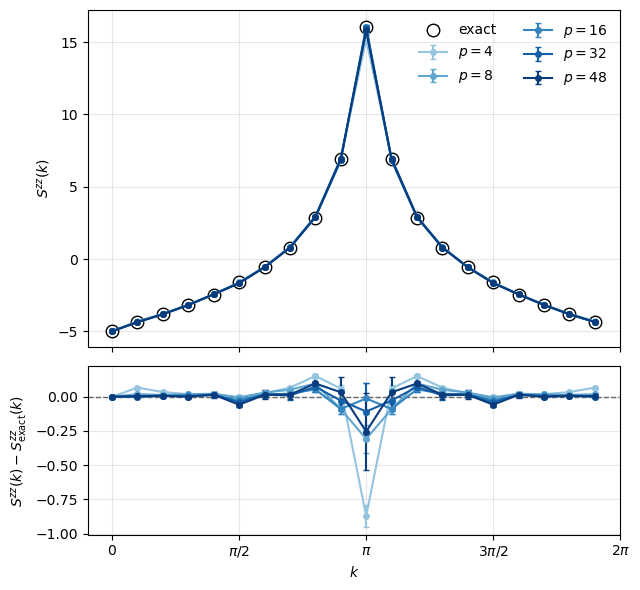

In [11]:
k = np.asarray(k_vectors)[:, 0]
szz_exact = np.ravel(exact['Szz'])
colors = plt.cm.Blues(np.linspace(0.4, 0.95, len(p_values)))   # light -> dark with p

fig, (ax, ax_d) = plt.subplots(2, 1, figsize=(6.5, 6), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})
for p, color in zip(p_values, colors):
    val, err = np.asarray(O['Szz'][p]), np.asarray(O_err['Szz'][p])
    ax.errorbar(k, val, yerr=err, marker='o', ms=4, lw=1.5, capsize=2,
                color=color, label=f'$p={p}$')
    ax_d.errorbar(k, val - szz_exact, yerr=err, marker='o', ms=4, lw=1.5,
                  capsize=2, color=color)
ax.plot(k, szz_exact, 'o', ms=9, mfc='none', mec='k', label='exact')
ax_d.axhline(0.0, color='0.4', ls='--', lw=1)
ax.set_ylabel('$S^{zz}(k)$')
ax_d.set_ylabel(r'$S^{zz}(k) - S^{zz}_\mathrm{exact}(k)$')
ax_d.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
                ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax_d.set_xlabel('$k$')
for a in (ax, ax_d):
    a.grid(alpha=0.3)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
plt.show()